# Water That Sells Itself · Japanese NLP deep dive

**IPSA The Time R Aqua** is a ¥4,400 watery lotion that won #2 overall in the @cosme Best Cosmetics Awards 2020.
A social-listening export holds 1,272 Japanese posts about it (Jul–Dec 2020). The brief asks five questions about Japanese consumers:
what **triggers** trial, what **holds them back**, how they see the **brand**, which **benefits** they feel and **where they buy**,
and then what a new beauty launch in Japan should learn from it.

The companion Power BI report answers those questions with a 218-keyword dictionary. This notebook asks the questions a dashboard can't:

1. **Did the dictionary miss anything?** Let the posts organise themselves with Japanese tokenisation and NMF topic modelling, then compare.
2. **Which words separate happy posts from the rest?** Weighted log-odds with an informative prior.
3. **Can we trust the vendor's sentiment labels?** A cross-validated text classifier plus a manual audit of every "negative" consumer post.
4. **Which themes travel together?** A co-occurrence network of the dictionary themes.
5. **Is the timeline real?** Separate consumer behaviour from how the data was collected.

### Key findings
* **The vendor's sentiment overstates negativity about 4×.** Only 8 of the 62 consumer posts it marked *Negative* actually criticise the product. 26 are praise that mentions a problem word ("my acne cleared up"). A keyword search turns up 9 real complaints that were labelled neutral or positive. That leaves at least **17 critical posts (1.5%)**, not 5.6%.
* **Real complaints are about the core promise.** They fall into three groups: *no visible effect* (7), *breakouts or irritation* (5) and *not moisturising enough* (4). Price shows up as hesitation weighed against the product's bestseller reputation. It is almost never the complaint itself (1 of 17).
* **Topic modelling confirms the dictionary and finds two gaps.** About 81% of consumer posts match at least one dictionary theme. A stable topic adds *moisture power vs price*, where value is judged against performance. A less stable one points to rival brands, and a direct count confirms them: **7% of consumer posts name a rival** (Albion 19, Muji 12, Orbis 11, Lancôme 10, SK-II 10). The dictionary has no theme for this.
* **Texture is what makes people happy.** さらっと (*silky-light*), テクスチャー (*texture*) and 浸透 (*absorbs*) are the words most tied to positive posts.
* **The December peak is real, but smaller than it looks.** 524 of 551 @cosme reviews sit in three three-week collection windows, which shows how the data was gathered rather than how consumers behaved. Twitter, which runs continuously, still peaks in December (167 posts, +72% on November), led by talk about the @cosme Best Cosmetics award.

In [1]:
# ---- where things live -------------------------------------------------------------------------
# Main portfolio folder. The notebook, ipsanlp.py and themes.py can sit in any subfolder of it;
# data and images folders can sit next to the notebook or directly in the main folder.
import os, sys
from pathlib import Path

MAIN_FOLDER = Path(r"C:\Users\Johanna\OneDrive\Documents\Portfolios\Radarr")
DATA_OVERRIDE = r""   # optional: full path of the IPSA .xlsx if it lives somewhere else

def first_existing(paths):
    return next((p for p in paths if p and p.exists()), None)

def code_folder():
    for p in [Path.cwd(), *Path.cwd().parents]:          # notebook started inside the project
        if (p / "ipsanlp.py").exists():
            return p
    for root in [MAIN_FOLDER, Path.cwd()]:                  # otherwise search the portfolio folder
        if root.exists():
            hits = sorted(root.rglob("ipsanlp.py"), key=lambda f: len(f.parts))
            if hits:
                return hits[0].parent
    return None

CODE = code_folder()
if CODE is None:
    raise FileNotFoundError(f"ipsanlp.py not found in {MAIN_FOLDER}. Keep ipsanlp.py and themes.py next to this notebook.")
os.chdir(CODE)
sys.path.insert(0, str(CODE))

def find_data():
    if DATA_OVERRIDE:
        return Path(DATA_OVERRIDE)
    folders = [CODE / "data", CODE, CODE.parent / "data", CODE.parent, MAIN_FOLDER / "data", MAIN_FOLDER]
    for folder in folders:
        if folder.exists():
            hits = sorted(f for f in folder.glob("*.xlsx") if "ipsa" in f.name.lower() and not f.name.startswith("~$"))
            if hits:
                return hits[0]
    hits = sorted((f for f in MAIN_FOLDER.rglob("*.xlsx") if "ipsa" in f.name.lower()), key=lambda f: len(f.parts)) if MAIN_FOLDER.exists() else []
    return hits[0] if hits else None

DATA = find_data()
if DATA is None or not DATA.exists():
    raise FileNotFoundError("IPSA workbook not found. Put the .xlsx in the data folder, or paste its full path into DATA_OVERRIDE.")

IMAGES = first_existing([CODE / "images", CODE.parent / "images", MAIN_FOLDER / "images"]) or (CODE / "images")
IMAGES.mkdir(exist_ok=True)

def save(fig, name):
    # every chart is also written to the images folder, ready for GitHub or Maven
    fig.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")

print("Code  :", CODE.name)
print("Data  :", DATA.name, "in", DATA.parent.name)
print("Images:", IMAGES.name)

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

import ipsanlp as nlp
from ipsanlp import g, PLUM, ROSE, PEACH, LILAC, GOLD, BERRY, MAUVE, INK, MUTED

nlp.style_charts()
pd.set_option("display.max_colwidth", 90)

Code  : pkg2
Data  : Ipsa_The_Time_Reset_Aqua_Japan_Jan_2020_to_Dec_2020.xlsx in data
Images: images


## 1 · The data and who is talking

The export mixes three voices. Media articles and retailer or campaign posts (giveaways, shop links, rankings) say little about how consumers feel,
so most of the analysis uses **consumer posts only**, with exact duplicate texts removed. The rule is the same one used in the Power BI model.

In [2]:
posts = nlp.load_posts(DATA)
print(f"{len(posts):,} posts · {posts.date.min():%d %b %Y} – {posts.date.max():%d %b %Y} · {posts.is_dup_text.sum()} duplicate texts")

overview = (posts.pivot_table(index="platform", columns="voice", values="text", aggfunc="count", fill_value=0)
                 .assign(Total=lambda t: t.sum(axis=1)).sort_values("Total", ascending=False))
overview.loc["Total"] = overview.sum()
overview

1,272 posts · 29 Jul 2020 – 31 Dec 2020 · 43 duplicate texts


voice,Consumer,Media,Retail & promo,Total
platform,,,,
Twitter,554,0,86,640
@cosme reviews,551,0,0,551
News (LexisNexis),0,55,0,55
Facebook,9,0,3,12
Forums,6,0,0,6
Instagram,3,0,1,4
News (online),0,3,0,3
Blogs,1,0,0,1
Total,1124,58,90,1272


In [3]:
consumer = posts[(posts.voice == "Consumer") & ~posts.is_dup_text].copy()
print(f"Consumer posts used for analysis: {len(consumer):,}  "
      f"({(consumer.platform == '@cosme reviews').mean():.0%} @cosme reviews, {(consumer.platform == 'Twitter').mean():.0%} Twitter)")
consumer.sentiment.value_counts(normalize=True).round(3).rename("vendor sentiment share").to_frame()

Consumer posts used for analysis: 1,106  (49% @cosme reviews, 49% Twitter)


,vendor sentiment share
sentiment,
Positive,0.737
Neutral,0.207
Negative,0.056


## 2 · Tokenising Japanese

Japanese has no spaces between words, so text has to be split into morphemes before any counting.
`janome` (a pure-Python morphological analyser) does this. Three tweaks make it work for skincare talk:

* **User dictionary:** the default dictionary breaks 保湿 (*moisturising*) into 保 + 湿る and 化粧水 (*lotion*) into 化粧 + 水, so 35 domain words are added.
* **Compound nouns:** consecutive nouns are merged (乾燥 + 肌 → 乾燥肌, *dry skin*).
* **Base forms and filtering:** verbs and adjectives are reduced to their dictionary form, while particles, auxiliaries, the brand name and generic words are dropped.

In [4]:
example = consumer.text.loc[2]
print(example[:70], "…\n")
print("janome :", " | ".join(f"{s}/{p}" for s, b, p in nlp.morphemes(example)[:16]), "…")
print("tokens :", nlp.tokenize(example))

敏感肌で自分に合う化粧水を探していて、口コミがよかったこちらを購入してみました。使った次の日から肌の調子がよく自分の肌に合っていると感じ、こ …

janome : 敏感肌/名詞 | で/接続詞 | 自分/名詞 | に/助詞 | 合う/動詞 | 化粧水/名詞 | を/助詞 | 探し/動詞 | て/助詞 | い/動詞 | て/助詞 | 、/記号 | 口コミ/名詞 | が/助詞 | よかっ/形容詞 | た/助動詞 …
tokens : ['敏感肌', '探す', '口コミ', '調子']


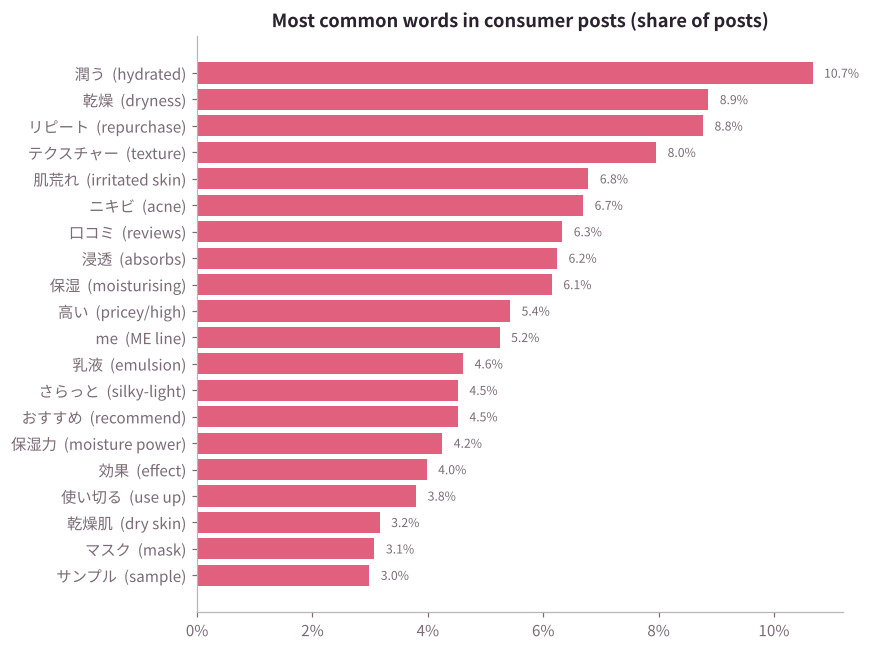

In [5]:
consumer["tokens"] = consumer.text.apply(nlp.tokenize)
posts["tokens"] = posts.text.apply(nlp.tokenize)

doc_freq = pd.Series([w for t in consumer.tokens for w in set(t)]).value_counts()
top = (doc_freq.head(20) / len(consumer))[::-1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([g(w) for w in top.index], top.values, color=ROSE)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Most common words in consumer posts (share of posts)")
for y, v in enumerate(top.values):
    ax.text(v + 0.002, y, f"{v:.1%}", va="center", fontsize=8, color=MUTED)
plt.tight_layout(); save(fig, "top words"); plt.show()

Even before modelling, the vocabulary tells the story: **dryness, irritated skin and acne** are the problems,
and **absorption, texture and moisturising** are the benefits. Reviews (口コミ) are the most common social cue.

## 3 · Topics without a dictionary (NMF)

Non-negative matrix factorisation on TF-IDF weights splits the consumer posts into topics without any labels.
To choose the number of topics *k*, each run is scored with **UMass coherence**, which checks whether a topic's top words really appear together in the same posts.

Document-term matrix: 1,106 posts × 328 terms


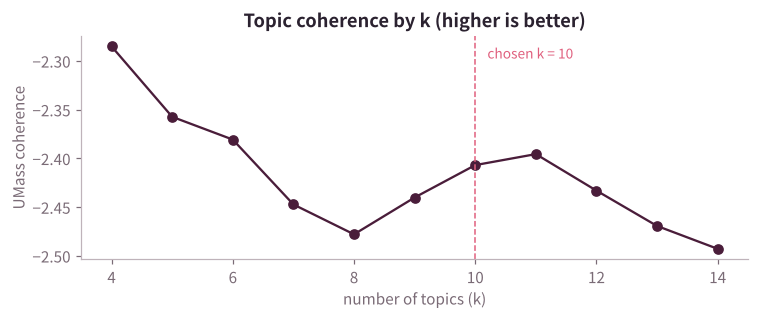

In [6]:
vec = TfidfVectorizer(tokenizer=str.split, lowercase=False, token_pattern=None, min_df=5, max_df=0.4, sublinear_tf=True)
X = vec.fit_transform(consumer.tokens.apply(" ".join))
vocab = np.array(vec.get_feature_names_out())
B = (X > 0).astype(int).tocsc()
print(f"Document-term matrix: {X.shape[0]:,} posts × {X.shape[1]:,} terms")

scores = []
for k in range(4, 15):
    H = NMF(k, init="nndsvda", random_state=0, max_iter=800).fit(X).components_
    scores.append((k, np.mean([nlp.umass_coherence(B, np.argsort(-h)[:10]) for h in H])))
scores = pd.DataFrame(scores, columns=["k", "coherence"])

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(scores.k, scores.coherence, marker="o", color=PLUM)
ax.axvline(10, color=ROSE, ls="--", lw=1)
ax.text(10.2, scores.coherence.max(), "chosen k = 10", color=ROSE, fontsize=9, va="top")
ax.set_xlabel("number of topics (k)"); ax.set_ylabel("UMass coherence")
ax.set_title("Topic coherence by k (higher is better)")
plt.tight_layout(); save(fig, "topic coherence"); plt.show()

Very small *k* scores well only because its topics are broad. Between 8 and 14, coherence peaks at **k = 10–11**.
I use **k = 10**: at 11 the extra topic is a thin "happy / want it" catch-all, while every topic at 10 can be named.

In [7]:
K = 10
nmf = NMF(K, init="nndsvda", random_state=0, max_iter=800)
W = nmf.fit_transform(X)
consumer["topic"] = W.argmax(axis=1)

TOPIC_NAMES = {
    0: "Tried it on reviews & samples",
    1: "Hydration claims (brand copy)",
    2: "Shop listings & links",
    3: "Repurchase & skin recovery",
    4: "Acne & mask breakouts",
    5: "Dry, sensitive skin in cold season",
    6: "Counter visits & the ME line",
    7: "Watery texture that sinks in",
    8: "Moisture power vs price",
    9: "Building a routine (emulsion, serum, rivals)",
}
topics = pd.DataFrame({
    "topic": [TOPIC_NAMES[t] for t in range(K)],
    "posts": [(consumer.topic == t).sum() for t in range(K)],
    "top words": ["  ·  ".join(g(w) for w in vocab[np.argsort(-nmf.components_[t])[:6]]) for t in range(K)],
}).sort_values("posts", ascending=False)
consumer["topic_name"] = consumer.topic.map(TOPIC_NAMES)
topics.style.hide(axis="index")

topic,posts,top words
Watery texture that sinks in,201,テクスチャー (texture) · 浸透 (absorbs) · さらっと (silky-light) · 保湿 (moisturising) · シャバシャバ (watery) · 浸透力 (absorption)
Moisture power vs price,180,高い (pricey/high) · 肌荒れ (irritated skin) · 保湿力 (moisture power) · 使い切る (use up) · 評価 (rating) · 刺激 (irritation)
Tried it on reviews & samples,159,口コミ (reviews) · 乾燥肌 (dry skin) · 期待 (expectation) · サンプル (sample) · 素敵 (lovely) · 気に入る (like it)
"Dry, sensitive skin in cold season",105,乾燥 (dryness) · 保湿 (moisturising) · 敏感肌 (sensitive skin) · 季節 (season) · 少ない (little) · ケア (care)
"Building a routine (emulsion, serum, rivals)",95,乳液 (emulsion) · クリーム (cream) · 美容液 (serum) · アルビオン (Albion (rival)) · 拭き取る (wipe-off) · おすすめ (recommend)
Repurchase & skin recovery,93,リピート (repurchase) · 戻る (come back) · 値段 (price) · 荒れる (break out) · お気に入り (favourite) · 治る (heal)
Counter visits & the ME line,87,me (ME line) · レギュラー (ME Regular) · マスク (mask) · コスメ (cosmetics) · 行く (go (counter)) · おすすめ (recommend)
Acne & mask breakouts,85,ニキビ (acne) · 治る (heal) · 経つ (time passes) · 効く (works) · 悩む (struggle) · 効果 (effect)
Hydration claims (brand copy),82,潤う (hydrated) · みずみずしい (dewy) · 作る (create) · 与える (give) · 保水成分 (water-holding agent) · 保護 (protect)
Shop listings & links,19,楽天 (Rakuten) · サイト (website) · 情報 (info) · 一覧 (list) · 確認 (check) · 経つ (time passes)


### Are the topics stable?

NMF can land on different solutions depending on how it is initialised. To check, I refit the model five times from random starting points.
Each run's topics are matched to the reference topics with the Hungarian algorithm on cosine similarity. A similarity close to 1 means the same topic came back.

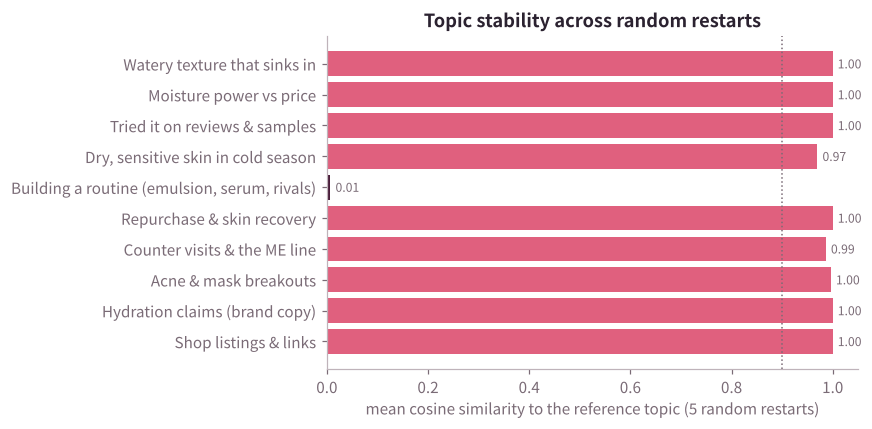

,cosine,top-10 word overlap
topic,,
Watery texture that sinks in,1.00,1.00
Moisture power vs price,1.00,1.00
Tried it on reviews & samples,1.00,1.00
"Dry, sensitive skin in cold season",0.97,0.67
"Building a routine (emulsion, serum, rivals)",0.01,0.00
Repurchase & skin recovery,1.00,1.00
Counter visits & the ME line,0.99,0.82
Acne & mask breakouts,1.00,0.67
Hydration claims (brand copy),1.00,1.00


In [8]:
runs = []
for seed in range(1, 6):
    H = NMF(K, init="random", random_state=seed, max_iter=1500).fit(X).components_
    order, sim = nlp.match_topics(nmf.components_, H)
    for t in range(K):
        ref_top = set(np.argsort(-nmf.components_[t])[:10])
        run_top = set(np.argsort(-H[order[t]])[:10])
        runs.append((TOPIC_NAMES[t], seed, sim[t], len(ref_top & run_top) / len(ref_top | run_top)))
stab = (pd.DataFrame(runs, columns=["topic", "seed", "cosine", "top-10 word overlap"])
          .groupby("topic")[["cosine", "top-10 word overlap"]].mean().loc[topics.topic])

fig, ax = plt.subplots(figsize=(8, 4))
colors = [ROSE if v >= 0.9 else PLUM for v in stab.cosine]
ax.barh(stab.index[::-1], stab.cosine[::-1], color=colors[::-1])
ax.axvline(0.9, color=MUTED, ls=":", lw=1)
ax.set_xlim(0, 1.05); ax.set_xlabel("mean cosine similarity to the reference topic (5 random restarts)")
ax.set_title("Topic stability across random restarts")
for y, v in enumerate(stab.cosine[::-1]):
    ax.text(min(v, 1.0) + 0.01, y, f"{v:.2f}", va="center", fontsize=8, color=MUTED)
plt.tight_layout(); save(fig, "topic stability"); plt.show()
stab.style.format("{:.2f}")

**Reading the stability check**
* **Nine of ten topics are robust.** They come back in every random restart with cosine ≥ 0.97 and mostly the same top words.
* **The routine topic is not robust.** In random restarts, *Building a routine* disappears: its words (emulsion, serum, cream) merge into *Dry, sensitive skin*, and a thin "want it / happy" topic takes its slot. Its reconstruction error is almost identical (29.07 vs 29.07), so the data cannot really tell the two solutions apart.
* So I treat the routine-and-rivals idea as a **hypothesis from the topic model** and test it directly with brand counts below, rather than quoting the topic's size.

### Do the discovered topics match the hand-built dictionary?

The heatmap shows, for each discovered topic, the share of its posts that the dictionary tags with each theme.
A strong diagonal-like pattern means the dictionary already captures that topic. A topic with no strong cell is something the dictionary missed.

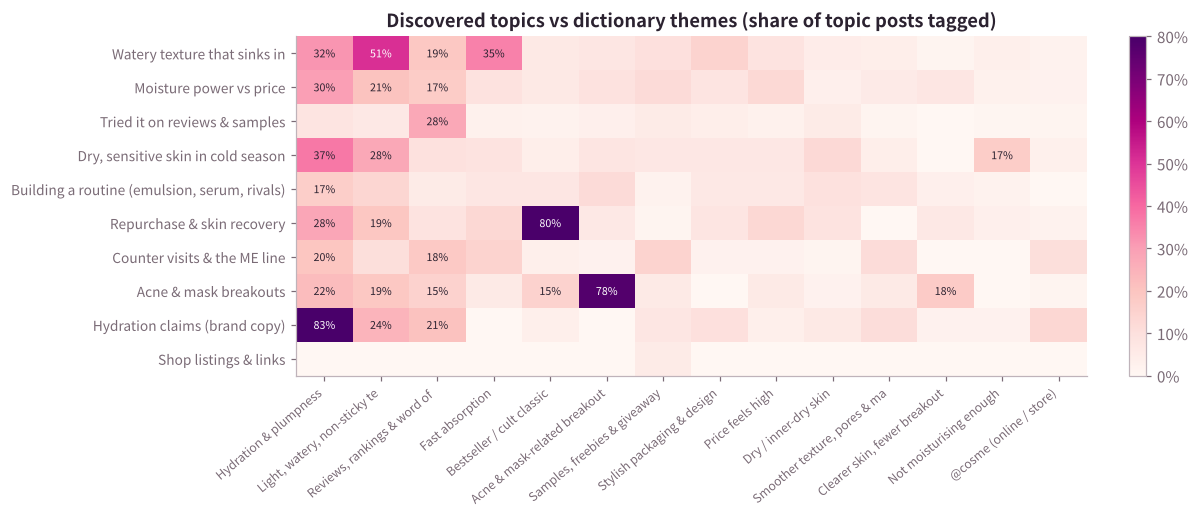

In [9]:
themes = nlp.tag_themes(consumer.text)
themes.index = consumer.index
key_themes = themes.sum().sort_values(ascending=False).head(14).index
heat = themes[key_themes].groupby(consumer.topic_name).mean()
heat = heat.loc[topics.topic]

fig, ax = plt.subplots(figsize=(11, 4.8))
im = ax.imshow(heat.values, cmap="RdPu", vmin=0, vmax=0.8, aspect="auto")
ax.set_xticks(range(len(key_themes)), [t[:28] for t in key_themes], rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(heat)), heat.index, fontsize=9)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if v >= 0.15:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.45 else INK)
ax.set_title("Discovered topics vs dictionary themes (share of topic posts tagged)")
plt.colorbar(im, ax=ax, fraction=0.02, format=plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); save(fig, "topics vs dictionary"); plt.show()

**Reading the heatmap**
* Most topics map cleanly onto dictionary themes, for example *Repurchase & skin recovery* → *Bestseller / cult classic* (80%) and *Acne & mask breakouts* → the acne theme (78%). Overall, **81%** of consumer posts carry at least one dictionary theme.
* **Moisture power vs price (180 posts, stable)** sets price next to moisturising power and irritation. Value is judged on performance, which the single *Price feels high* theme (7%) does not capture.
* **Building a routine (95 posts, not stable)** has no theme above 20%. It suggests people judge the lotion next to an emulsion, a serum and rival brands. The direct count below confirms the rival part.
* **Hydration claims** reads like product-description copy (保水成分 *water-holding agent*, 与える *give*). Some shop text slips past the consumer filter, so the voice rule could be tightened.

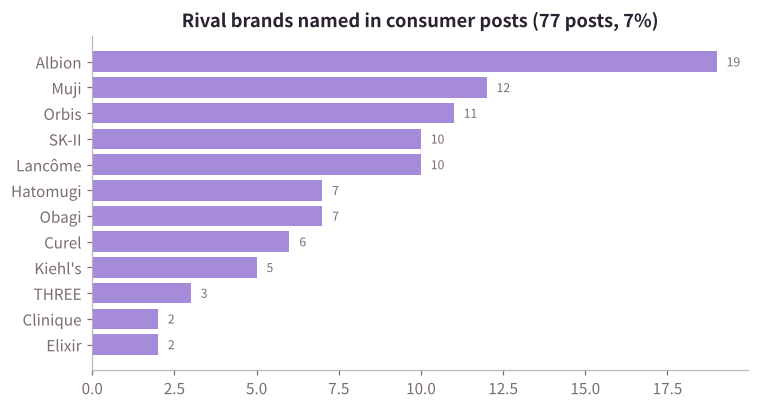

The dictionary has no rival-brand theme: 29% of these posts carry no dictionary theme at all.


In [10]:
RIVALS = {"Albion": "アルビオン|albion", "Muji": "無印", "Orbis": "オルビス|orbis", "Lancôme": "ランコム|lancome", "SK-II": "sk-ii|skii|sk2",
          "Obagi": "オバジ|obagi", "Hatomugi": "ハトムギ", "Curel": "キュレル|curel", "Kiehl's": "キールズ|kiehl", "THREE": "three",
          "Elixir": "エリクシール", "Clinique": "クリニーク"}
low = consumer.text.str.lower()
rivals = pd.DataFrame({b: low.str.contains(p) for b, p in RIVALS.items()})
mentions_rival = rivals.any(axis=1)
counts = rivals.sum().sort_values()
counts = counts[counts > 0]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(counts.index, counts.values, color=LILAC)
for y, v in enumerate(counts.values):
    ax.text(v + 0.3, y, str(v), va="center", fontsize=8, color=MUTED)
ax.set_title(f"Rival brands named in consumer posts ({mentions_rival.sum()} posts, {mentions_rival.mean():.0%})")
plt.tight_layout(); save(fig, "rival brands"); plt.show()
print(f"The dictionary has no rival-brand theme: {1 - themes[mentions_rival.values].any(axis=1).mean():.0%} of these posts carry no dictionary theme at all.")

## 4 · Which words separate positive posts from the rest?

Raw frequency is misleading here, because common words like 肌荒れ (*irritated skin*) appear everywhere.
**Weighted log-odds with an informative Dirichlet prior** (Monroe, Colaresi & Quinn, 2008) compares the two groups while shrinking rare words toward the overall rate.
The z-score shows how strongly a word leans to one side, and |z| > 1.96 is roughly significant.

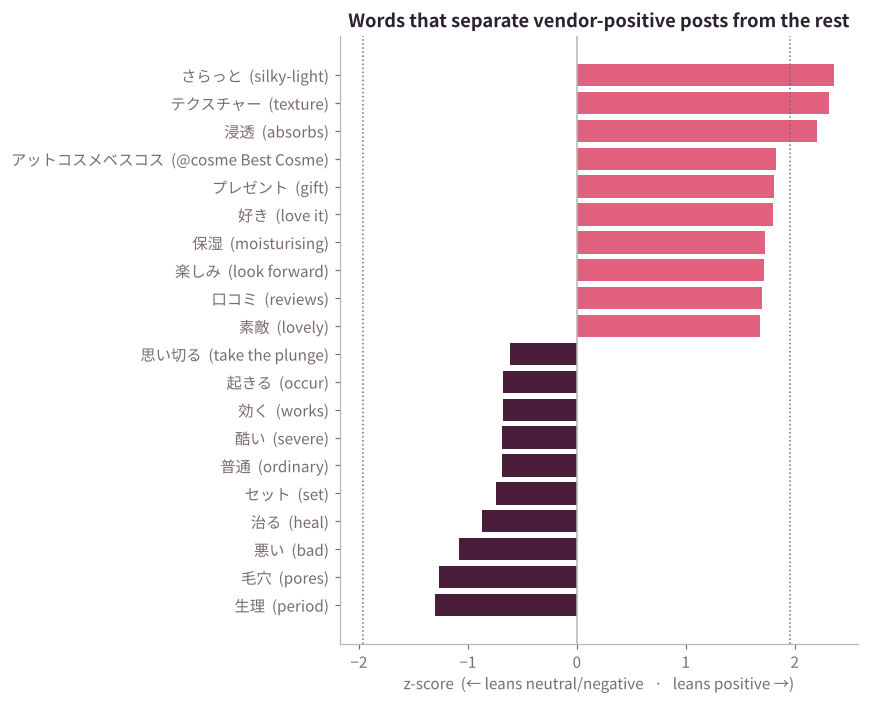

In [11]:
lo = nlp.weighted_log_odds(consumer.loc[consumer.sentiment == "Positive", "tokens"],
                           consumer.loc[consumer.sentiment != "Positive", "tokens"],
                           posts.tokens)
show = pd.concat([lo.head(10), lo.tail(10)])

fig, ax = plt.subplots(figsize=(8, 6.5))
colors = [ROSE if z > 0 else PLUM for z in show.z]
ax.barh([g(w) for w in show.word], show.z, color=colors)
ax.axvline(0, color="#BFB3BA", lw=1)
for x in (-1.96, 1.96):
    ax.axvline(x, color=MUTED, ls=":", lw=1)
ax.set_xlabel("z-score  (← leans neutral/negative   ·   leans positive →)")
ax.set_title("Words that separate vendor-positive posts from the rest")
plt.tight_layout(); save(fig, "log odds words"); plt.show()

**Reading the chart**
* The positive side is about the **sensory experience**: silky-light, texture, absorption, plus *gift* and the *@cosme Best Cosme* award.
* The other side is about **skin problems**: period, pores, heal, severe. Many of these posts praise the product for *fixing* the problem.
* No word on the negative side passes |z| = 1.96. If the "not positive" posts were real complaints, words like 合わない (*didn't suit*) would stand out. Instead, problem words dominate. That pattern suggests the vendor scores **mentions of skin problems as negative sentiment**, which the next section tests.

## 5 · Can we trust the vendor's sentiment labels?

The dashboard reports 72% positive and 5% negative, but those labels come from the listening vendor's engine. Two checks:

1. **Can a model learn the labels?** If the labels are consistent, a character n-gram logistic regression should reproduce them well under 5-fold cross-validation.
2. **Manual audit:** I read every consumer post the vendor marked *Negative* (62), plus 68 vendor positive/neutral posts that contain complaint phrases
   (合わない *didn't suit*, 潤わない *not moisturising*, 効果を感じない *no effect*, and similar), and labelled what each one actually says.
   The labels are stored in `ipsanlp.py` (`AUDIT_ROWS`) and exported to `data/manual sentiment audit.csv`.

In [12]:
y = consumer.sentiment.values
Xc = TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3), min_df=3, sublinear_tf=True).fit_transform(consumer.text.str[:1000])
clf = LogisticRegression(max_iter=3000, C=4, class_weight="balanced")
proba = cross_val_predict(clf, Xc, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")
classes = np.unique(y)
pred = classes[proba.argmax(axis=1)]
print(classification_report(y, pred, digits=2))

cm = pd.DataFrame(confusion_matrix(y, pred, labels=classes), index=[f"vendor {c}" for c in classes], columns=[f"model {c}" for c in classes])
cm

              precision    recall  f1-score   support

    Negative       0.32      0.11      0.17        62
     Neutral       0.45      0.38      0.41       229
    Positive       0.82      0.90      0.86       815

    accuracy                           0.75      1106
   macro avg       0.53      0.46      0.48      1106
weighted avg       0.72      0.75      0.73      1106



,model Negative,model Neutral,model Positive
vendor Negative,7,30,25
vendor Neutral,10,87,132
vendor Positive,5,78,732


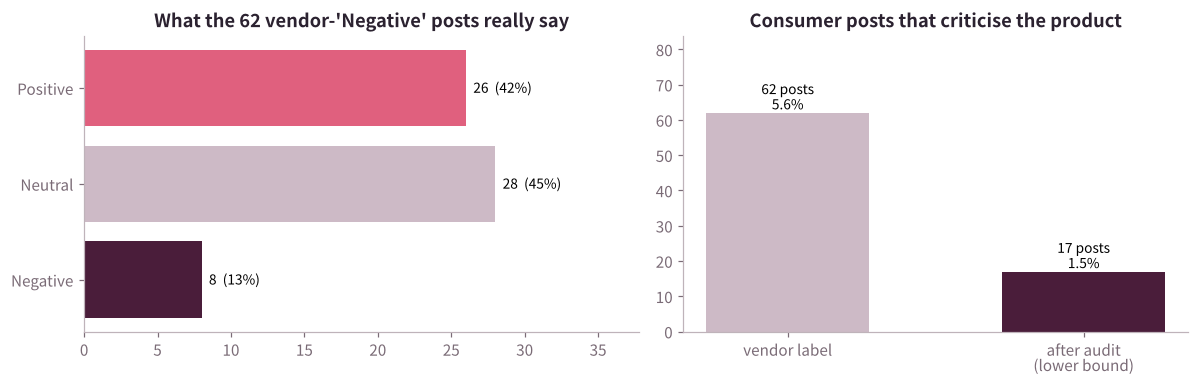

Examples the vendor marked Negative that are actually praise (English translation):
  · ベタつかないです！…
      "Not sticky!"
  · IPSA ザ・タイムR アクア肌荒れが起きにくくなった、来年も使う https:…
      "IPSA The Time R Aqua: my skin breaks out less easily now. I'll keep using it next year."
  · 生理中の肌荒れ(ニキビ、赤み)がこれを使ってると全く起きなかったです。また、生理…
      "While using this I had no period breakouts (acne, redness) at all. My previous lotion sometimes stung during my period, but that didn't happen…"
  · ニキビがひどい時に2回ほどリピートで購入しました。テクスチャーが水みたいなのでど…
      "I repurchased it twice when my acne was bad. The texture is like water so I wondered how it would work… but it sinks right in and my skin turns plump."


In [13]:
audit = nlp.load_audit()   # same table as data/manual_sentiment_audit.csv
vendor_neg = audit[audit["sample"] == "vendor Negative"]
assert set(vendor_neg.row) == set(consumer.index[consumer.sentiment == "Negative"]), "audit rows must match the consumer negatives"

hidden = audit[audit["sample"] != "vendor Negative"]
summary = vendor_neg.audited_label.value_counts().reindex(["Positive", "Neutral", "Negative"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
ax.barh(summary.index[::-1], summary.values[::-1], color=[PLUM, MAUVE, ROSE])
for i, v in enumerate(summary.values[::-1]):
    ax.text(v + 0.5, i, f"{v}  ({v / summary.sum():.0%})", va="center", fontsize=9)
ax.set_title(f"What the {summary.sum()} vendor-'Negative' posts really say")
ax.set_xlim(0, summary.max() * 1.35)

true_neg = int((vendor_neg.audited_label == "Negative").sum()) + len(hidden)
ax = axes[1]
vals = [int((consumer.sentiment == "Negative").sum()), true_neg]
ax.bar(["vendor label", "after audit\n(lower bound)"], vals, color=[MAUVE, PLUM], width=0.55)
for i, v in enumerate(vals):
    ax.text(i, v + 1, f"{int(v)} posts\n{v / len(consumer):.1%}", ha="center", fontsize=9)
ax.set_title("Consumer posts that criticise the product")
ax.set_ylim(0, max(vals) * 1.35)
plt.tight_layout(); save(fig, "sentiment audit"); plt.show()

print("Examples the vendor marked Negative that are actually praise (English translation):")
for r in vendor_neg[vendor_neg.audited_label == "Positive"].head(4).itertuples():
    print(f"  · {posts.loc[r.row, 'text'][:40]}…\n      \"{nlp.translation(r.row)}\"")

### The real complaints, in English

All 17 critical posts, with the vendor's label, the type of complaint and a hand translation.

In [14]:
complaints = audit[audit.audited_label == "Negative"].copy()
complaints["complaint type"] = complaints.row.map(nlp.complaint_type)
complaints["English translation"] = complaints.row.map(nlp.translation)
complaints["platform"] = complaints.row.map(posts.platform)
order = ["No visible effect", "Breakouts / irritation", "Not moisturising enough", "Poor value"]
complaints["complaint type"] = pd.Categorical(complaints["complaint type"], order, ordered=True)
print(complaints["complaint type"].value_counts().reindex(order).to_string())
(complaints.sort_values(["complaint type", "vendor_label"])[["complaint type", "vendor_label", "platform", "English translation"]]
           .rename(columns={"vendor_label": "vendor label"})
           .style.hide(axis="index").set_properties(subset=["English translation"], **{"text-align": "left", "white-space": "normal"}))

complaint type
No visible effect          7
Breakouts / irritation     5
Not moisturising enough    4
Poor value                 1


complaint type,vendor label,platform,English translation
No visible effect,Negative,@cosme reviews,"The reviews are great, but I couldn't feel it on my skin, which is disappointing. My skin is dry and gets rough, so I bought it with high hopes… Do I have to pair it with ME from the same line? Half is still left…"
No visible effect,Negative,@cosme reviews,"I tried it because the reviews were good. I used up a whole bottle; it wasn't bad, but nothing in particular changed, so I can't really say. Smaller pores, no flaking, fewer wrinkles…"
No visible effect,Negative,@cosme reviews,"They said it refills moisture like a tank… I expected too much (lol). Even the sample was neither good nor bad, but I gave in to its reputation and bought it…"
No visible effect,Negative,@cosme reviews,"Used two bottles. My rough skin didn't improve. There was no irritation so I bought a second one, but I saw no benefit in continuing and stopped."
No visible effect,Negative,@cosme reviews,"You can splash it on, but it felt a bit sticky. I didn't feel much effect."
No visible effect,Neutral,@cosme reviews,"Used it up but felt no particular benefit, so it felt expensive too. Like… water? Disappointing for something always in the rankings."
No visible effect,Neutral,Twitter,"Bought the IPSA emulsion and The Time R Aqua as a set in early September. Both are fresh and light! For me, I didn't feel much effect. Not enough for pores or moisture…"
Breakouts / irritation,Negative,Twitter,"After switching to HABA squalane + Orbis U lotion even my pre-period acne stopped, but the dry pores on my cheeks stayed. I switched to IPSA The Time R Aqua and the pre-period acne came back. Still a skincare nomad."
Breakouts / irritation,Negative,@cosme reviews,"Bought it because I kept reading that it works on acne. Result: maybe bad timing before my period, but I broke out as usual. It isn't an acne product, so I guess it can't be helped…"
Breakouts / irritation,Neutral,@cosme reviews,Unfortunately it didn't suit my skin. It gives me acne.


**What the audit shows**
* The classifier learns *Positive* well (F1 0.86) but not *Negative* (F1 0.17). When a model cannot reproduce a label from the text, the label itself is usually inconsistent.
* Of the 62 vendor-negative consumer posts, **8 (13%)** criticise the product, **26 (42%)** are praise that mentions acne, breakouts or dryness, and **28 (45%)** are neutral (questions, hauls, routine lists).
* The complaint-phrase search turns up **9 real complaints** that the vendor had labelled neutral or positive. So at least **17 posts (1.5% of consumer posts)** are critical, against the 5.6% reported.
* The 17 complaints group into **no visible effect** (7), **breakouts or irritation** (5), **not moisturising enough** (4) and **poor value** (1).

*Implication for the dashboard:* "Negative %" by theme is unreliable for problem-solving themes such as acne, which look worse than they are. Re-score sentiment, or show the audited figures, before using it for decisions.

## 6 · Which themes travel together?

Each edge links two dictionary themes that appear in the same consumer posts more often than chance would predict.
That means a **lift** above 1.5 with at least 8 shared posts. Node size is the number of posts and colour is the brief question the theme answers.

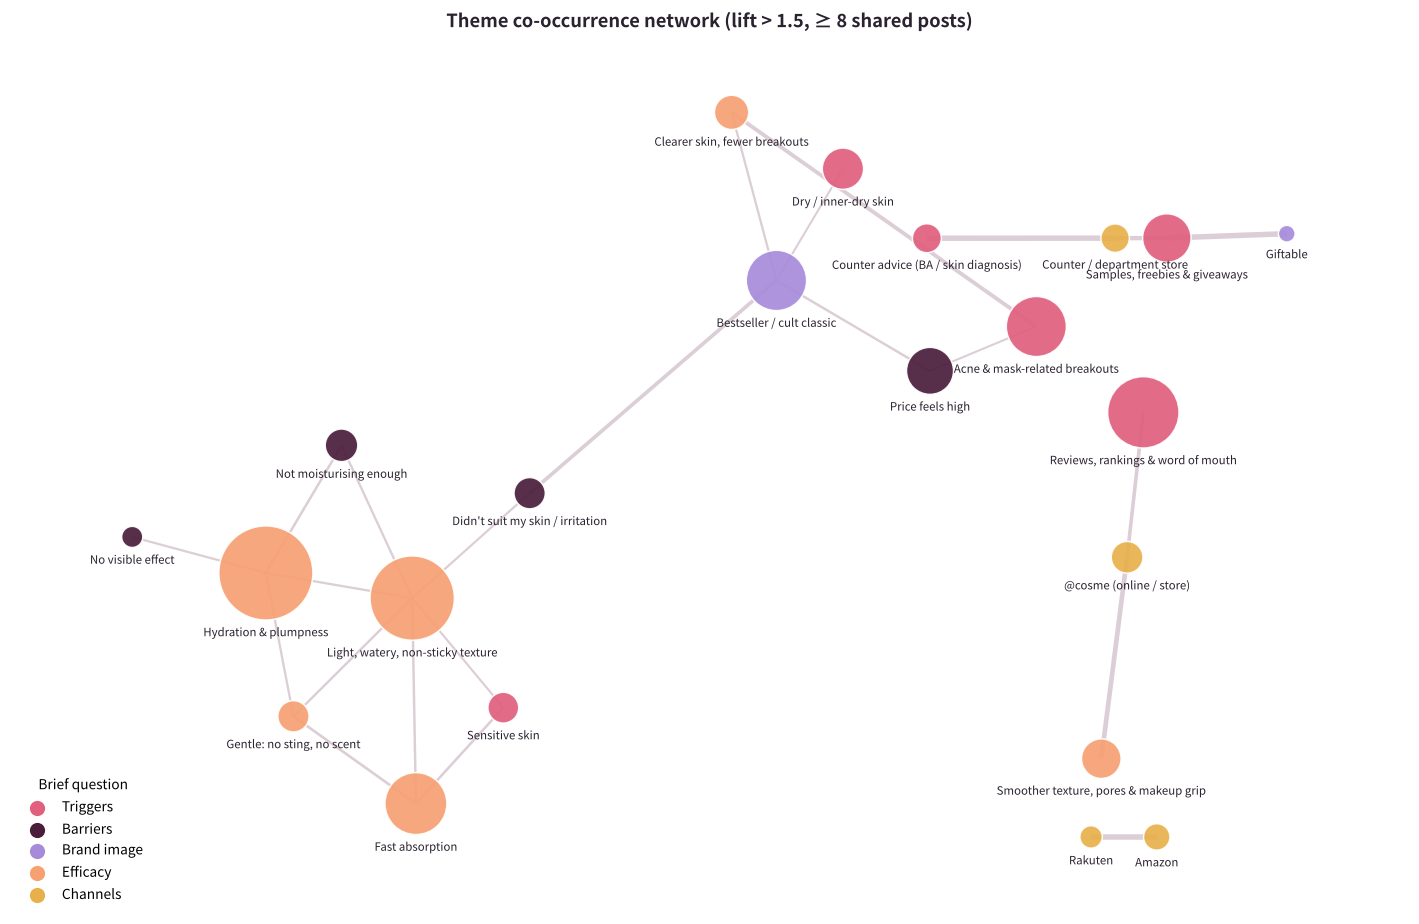

theme A,theme B,shared posts,lift
Amazon,Rakuten,16,39.3
Counter advice (BA / skin diagnosis),Counter / department store,13,16.5
"Samples, freebies & giveaways",Giftable,8,10.5
"Smoother texture, pores & makeup grip",@cosme (online / store),9,4.9
"Samples, freebies & giveaways",Counter / department store,10,4.5
Acne & mask-related breakouts,"Clearer skin, fewer breakouts",19,3.9
Didn't suit my skin / irritation,Bestseller / cult classic,15,3.6
"Reviews, rankings & word of mouth",@cosme (online / store),21,3.5


In [15]:
counts = themes.sum()
nodes = counts[counts >= 10].index
n = len(themes)
G = nx.Graph()
for t in nodes:
    G.add_node(t, size=counts[t], q=nlp.THEME_QUESTION[t])
for i, a in enumerate(nodes):
    for b in nodes[i + 1:]:
        both = int((themes[a] & themes[b]).sum())
        if both >= 8:
            lift = both * n / (counts[a] * counts[b])
            if lift > 1.5:
                G.add_edge(a, b, weight=lift, both=both)
G.remove_nodes_from([v for v in list(G) if G.degree(v) == 0])

# lay out each connected component on its own so small clusters don't crowd the big one
comps = sorted(nx.connected_components(G), key=len, reverse=True)
pos, slots = {}, [(0.0, 0.0, 2.2), (2.6, 0.9, 0.9), (2.6, -0.4, 0.7), (2.6, -1.4, 0.5), (2.6, -2.1, 0.4)]
for comp, (cx, cy, scale) in zip(comps, slots):
    sub = G.subgraph(comp)
    layout = nx.kamada_kawai_layout(sub) if len(comp) > 2 else {v: np.array([i * 0.6 - 0.3, 0.0]) for i, v in enumerate(comp)}
    for v, (x, y) in layout.items():
        pos[v] = np.array([cx + x * scale, cy + y * scale])
fig, ax = plt.subplots(figsize=(13, 8.5))
nx.draw_networkx_edges(G, pos, ax=ax, width=[0.6 + 0.5 * min(G[u][v]["weight"], 6) for u, v in G.edges], edge_color="#D9C9D2", alpha=0.9)
sizes = {v: 12 * G.nodes[v]["size"] for v in G}
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[sizes[v] for v in G],
                       node_color=[nlp.QUESTION_COLORS[G.nodes[v]["q"]] for v in G], alpha=0.92, linewidths=1, edgecolors="white")
for v, (x, y) in pos.items():   # labels just below each bubble
    ax.annotate(v, (x, y), xytext=(0, -np.sqrt(sizes[v]) / 2 - 4), textcoords="offset points", ha="center", va="top", fontsize=7.5, color=INK)
for q, c in nlp.QUESTION_COLORS.items():
    ax.scatter([], [], s=80, color=c, label=q[2:])
ax.legend(loc="lower left", frameon=False, fontsize=9, title="Brief question", title_fontsize=9)
ax.set_title("Theme co-occurrence network (lift > 1.5, ≥ 8 shared posts)")
ax.axis("off"); plt.tight_layout(); save(fig, "theme network"); plt.show()

edges = (pd.DataFrame([(u, v, d["both"], d["weight"]) for u, v, d in G.edges(data=True)], columns=["theme A", "theme B", "shared posts", "lift"])
           .sort_values("lift", ascending=False).head(8))
edges.style.hide(axis="index").format({"lift": "{:.1f}"})

**Reading the network**
* **The core promise is one cluster.** Texture, absorption, hydration, gentleness and sensitive skin all link to each other. The two hydration complaints, *not moisturising enough* (lift 2.1 with hydration) and *no visible effect* (1.8), attach to the same hydration node. People who are disappointed are disappointed by the core claim, not by something else.
* **A hype gap:** *didn't suit my skin* co-occurs with *bestseller / cult classic* (lift 3.7). Unhappy users often say they bought it *because* everyone recommends it. Popularity raises expectations the product then has to meet.
* **Price is weighed against reputation and need.** *Price feels high* links to *bestseller* (2.1) and to *acne* (1.5), not to complaints.
* **Trial runs through people and places.** Reviews link to @cosme (3.5). Counters link to BA advice and skin diagnosis (16.5) and to samples (4.5). Samples link to giftability (10.5).
* **Amazon and Rakuten appear together** (lift 39), mostly in shop-listing posts rather than in consumer stories.

## 7 · Is the timeline real?

A monthly chart of all posts shows December as the peak, which matches the @cosme award. Splitting the series by platform tells a more careful story.

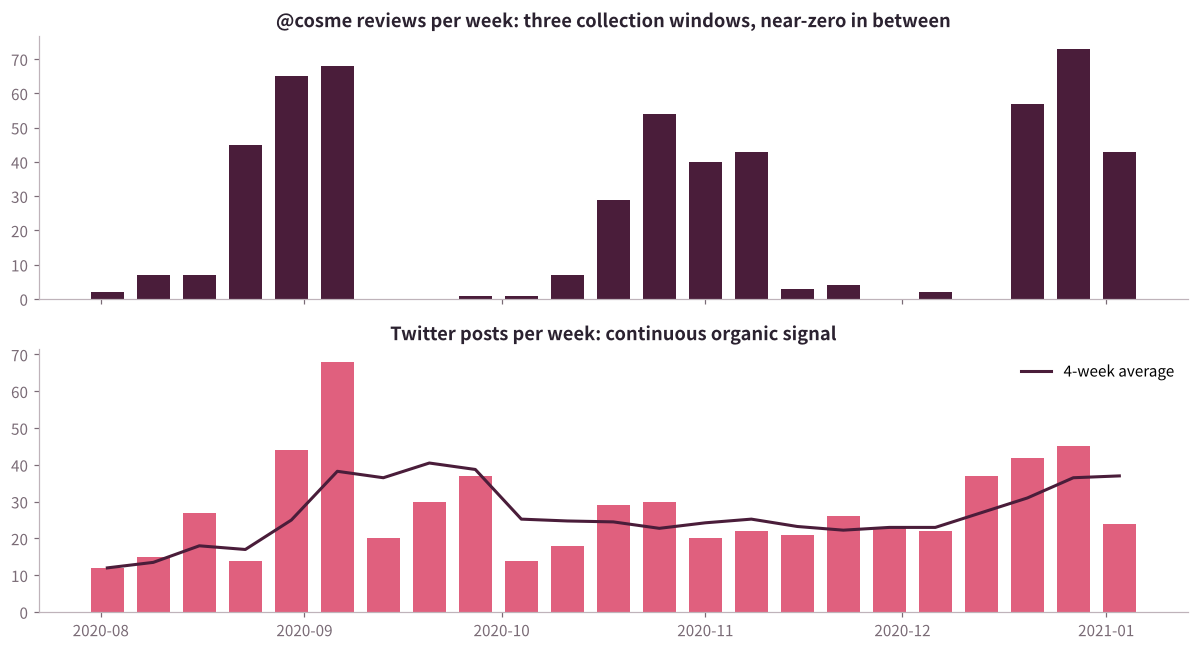

Twitter posts per month: {'2020-07': 8, '2020-08': 117, '2020-09': 146, '2020-10': 105, '2020-11': 97, '2020-12': 167}
@cosme reviews fall on 80 of 154 days; 524 of 551 sit in three windows (16 Aug–6 Sep, 16 Oct–8 Nov, 16–31 Dec).


In [16]:
daily = posts.assign(day=posts.date.dt.floor("D")).pivot_table(index="day", columns="platform", values="text", aggfunc="count", fill_value=0)
weekly = daily.resample("W-SUN").sum()
cosme_days = (daily["@cosme reviews"] > 0)
gaps = cosme_days[~cosme_days].index

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].bar(weekly.index, weekly["@cosme reviews"], width=5, color=PLUM)
axes[0].set_title("@cosme reviews per week: three collection windows, near-zero in between")
axes[1].bar(weekly.index, weekly["Twitter"], width=5, color=ROSE)
axes[1].plot(weekly.index, weekly["Twitter"].rolling(4, min_periods=1).mean(), color=PLUM, lw=2, label="4-week average")
axes[1].set_title("Twitter posts per week: continuous organic signal")
axes[1].legend(frameon=False)
plt.tight_layout(); save(fig, "timeline by platform"); plt.show()

tw = posts[posts.platform == "Twitter"].groupby(posts.date.dt.to_period("M")).size()
windows = daily.index[daily["@cosme reviews"] > 0]
print("Twitter posts per month:", {str(k): int(v) for k, v in tw.items()})
print(f"@cosme reviews fall on {cosme_days.sum()} of {len(cosme_days)} days; "
      f"{daily.loc['2020-08-16':'2020-09-06', '@cosme reviews'].sum() + daily.loc['2020-10-16':'2020-11-08', '@cosme reviews'].sum() + daily.loc['2020-12-16':'2020-12-31', '@cosme reviews'].sum()} "
      f"of {daily['@cosme reviews'].sum()} sit in three windows (16 Aug–6 Sep, 16 Oct–8 Nov, 16–31 Dec).")

**Reading the timeline**
* **@cosme reviews come in three blocks** (16 Aug–6 Sep, 16 Oct–8 Nov, 16–31 Dec) with almost nothing in between. On a site where reviews are posted every day, that pattern points to the listening tool collecting in batches. All-platform monthly totals therefore reflect the collection windows as much as consumer interest.
* **Twitter is collected continuously and gives the honest trend.** It rose to 146 posts in September, dipped to about 100 in October and November, and peaked at **167 in December**. The late-December tweets are driven by the award: in 14–31 Dec, "2位" (#2) appears 15 times and Best Cosme 17 times.
* For trend charts and launch-timing decisions, use the continuous channel, or normalise each platform by its collection days.

## 8 · What this adds to the brief

| Brief question | What the dashboard said | What this notebook adds |
|---|---|---|
| **Triggers** | Reviews and rankings, mask breakouts, samples | 7% of posts name a **rival brand** (Albion, Muji, Orbis, Lancôme, SK-II), usually while switching or pairing products. Counter skin diagnosis is a trigger in its own right. |
| **Barriers** | Price, not moisturising, needing ME | Real complaints are rare (≥ 1.5%) and centre on **no visible effect**. Price is weighed against reputation and is rarely the complaint. There is a **hype gap**: people who say it didn't suit them often mention its bestseller status. |
| **Brand image** | Stylish bestseller, age-neutral | Confirmed: repurchase and recovery stories are among the clearest topics. |
| **Efficacy** | Hydration, light texture, absorption | **Texture is the emotional driver**: the words most tied to positive posts are sensory. |
| **Channels** | @cosme, counters, Amazon, Rakuten | Online marketplaces show up mainly in shop listings. Consumer stories run through @cosme and counters. |

**For a new beauty launch in Japan**
1. **Audit the listening vendor's sentiment before reporting it.** Here it overstated negativity about 4× and made problem-solving themes look like weaknesses.
2. **Promise what users can feel quickly.** The main complaint is "no visible effect", so lead with texture and absorption (felt at once) and set realistic expectations for slower claims.
3. **Use counters and samples to manage the hype gap.** Counters link to skin diagnosis and samples, so a try-before-you-buy step filters out mismatched skin types before they become complaints.
4. **Plan to be judged inside a routine.** Show pairings (emulsion, serum) and expect direct comparison with rival brands.
5. **Track trends on continuous channels.** Batch-collected review sites distort timing, while award season (Dec) shows up clearly on Twitter.

### Limitations and next steps
* The manual audit was done by one reader. A second annotator and an agreement score (Cohen's κ) would make it publishable.
* Topic modelling on about 1,100 short posts is noisy. Nine of ten topics survive random restarts, but the *building a routine* topic does not, so routine and rival findings rest on direct brand counts.
* With a Japanese transformer model (e.g. a BERT fine-tuned on product reviews), sentiment could be re-scored for all posts instead of only an audited sample.
* Engagement metrics exist for Twitter only, so reach-weighted results would need a different data source.